# DSCI 552 - Homework 7

Name: Gao Wang  
GitHub Username: Gavinfornever  
USC ID: 8103152166

Run all cells from the repository root. The data path is relative. Outputs are compact for the 20-page submission limit.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, hamming_loss, silhouette_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

SEED = 552
LABELS = ["Family", "Genus", "Species"]
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})


## 1. Multi-class and multi-label classification with SVMs

### (a) Data and reproducible 70/30 split

Each call has 22 MFCC predictors and three categorical labels. `RecordID` is an identifier and is excluded. One joint split is shared by all three label models. Stratification by species preserves the rare species in both portions; each species maps to one genus and family.

In [2]:
csv_path = Path("data") / "Anuran Calls (MFCCs)" / "Frogs_MFCCs.csv"
frog = pd.read_csv(csv_path)
feature_columns = [c for c in frog if c.startswith("MFCCs_")]
X = frog[feature_columns]
y = frog[LABELS]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y["Species"])
assert X.shape == (7195, 22) and len(X_train) + len(X_test) == 7195
display(pd.DataFrame({"instances": [len(frog)], "train": [len(X_train)],
                      "test": [len(X_test)], "MFCC_features": [len(feature_columns)],
                      "families": [y.Family.nunique()], "genera": [y.Genus.nunique()],
                      "species": [y.Species.nunique()]}))


,instances,train,test,MFCC_features,families,genera,species
0,7195,5036,2159,22,4,8,10


### (b)i. Evaluation measures

Exact match is the fraction of calls for which **all three** labels are right. Hamming loss is the number of incorrect label entries divided by three times the number of calls. Hamming score here is one minus Hamming loss, the mean fraction of label entries correct. Mean Hamming distance is the mean number of wrong entries per call, so distance equals three times Hamming loss. These definitions apply to the three categorical columns, with one class predicted for each column.

In [3]:
def multi_label_metrics(truth, prediction):
    actual = np.asarray(truth)
    predicted = np.asarray(prediction)
    mismatches = actual != predicted
    return {"exact_match": np.mean(~mismatches.any(axis=1)),
            "hamming_distance": mismatches.sum(axis=1).mean(),
            "hamming_score": 1 - mismatches.mean(),
            "hamming_loss": mismatches.mean()}


def evaluate_models(models, X_holdout, truth, method):
    predicted = pd.DataFrame({label: models[label].predict(X_holdout)
                              for label in LABELS}, index=X_holdout.index)
    overall = {"method": method, **multi_label_metrics(truth[LABELS], predicted[LABELS])}
    per_label = {label: accuracy_score(truth[label], predicted[label]) for label in LABELS}
    return overall, per_label, predicted


### (b)ii. Gaussian-kernel one-versus-rest SVM

For each label, a standardized RBF SVM is wrapped in a one-versus-rest classifier. Ten stratified folds choose C and gamma from a prespecified logarithmic grid. The scaler is fitted only on each fold's training portion. The untouched 30% test set is evaluated after tuning.

In [4]:
# AI prompt (scope: three independent SVM searches): "For each of Family, Genus, and Species, tune an RBF one-versus-rest SVM with ten stratified folds. Keep scaling inside the CV pipeline, then evaluate all three labels together on the untouched test set."
def tune_per_label(builder, grid, method):
    models, search_rows = {}, []
    for label in LABELS:
        folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
        search = GridSearchCV(builder(), grid, cv=folds, scoring="accuracy",
                              n_jobs=4, refit=True)
        search.fit(X_train, y_train[label])
        models[label] = search.best_estimator_
        search_rows.append({"method": method, "label": label,
                            "CV_accuracy": search.best_score_, **search.best_params_})
    return models, pd.DataFrame(search_rows)


def rbf_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("svm", OneVsRestClassifier(SVC(kernel="rbf", cache_size=400))),
    ])


rbf_models, rbf_search = tune_per_label(
    rbf_model, {"svm__estimator__C": [0.1, 1, 10],
                "svm__estimator__gamma": [0.01, 0.1, 1]}, "RBF OvR")
rbf_report, rbf_per_label, rbf_predictions = evaluate_models(
    rbf_models, X_test, y_test, "RBF OvR")
display(rbf_search.round(4))
display(pd.DataFrame([rbf_report]).round(4))


,method,label,CV_accuracy,svm__estimator__C,svm__estimator__gamma
0,RBF OvR,Family,0.9911,10,0.1
1,RBF OvR,Genus,0.9883,10,0.1
2,RBF OvR,Species,0.9861,10,0.1


,method,exact_match,hamming_distance,hamming_score,hamming_loss
0,RBF OvR,0.9843,0.0329,0.989,0.011


### (b)iii. L1-penalized linear SVM

The L1 penalty is applied to linear SVM coefficients (`dual=False`). Ten-fold CV selects C separately for Family, Genus, and Species. Features are standardized within each fold.

In [5]:
def l1_model(class_weight=None):
    return Pipeline([
        ("scale", StandardScaler()),
        ("svm", OneVsRestClassifier(LinearSVC(penalty="l1", dual=False,
                                              class_weight=class_weight,
                                              max_iter=10000, random_state=SEED))),
    ])


l1_models, l1_search = tune_per_label(
    lambda: l1_model(), {"svm__estimator__C": [0.01, 0.1, 1, 10]}, "L1 linear OvR")
l1_report, l1_per_label, l1_predictions = evaluate_models(
    l1_models, X_test, y_test, "L1 linear OvR")
display(l1_search.round(4))
display(pd.DataFrame([l1_report]).round(4))


,method,label,CV_accuracy,svm__estimator__C
0,L1 linear OvR,Family,0.9382,1
1,L1 linear OvR,Genus,0.9523,10
2,L1 linear OvR,Species,0.9575,1


,method,exact_match,hamming_distance,hamming_score,hamming_loss
0,L1 linear OvR,0.9166,0.1528,0.9491,0.0509


### (b)iv. Remedy for class imbalance

The alternative is inverse-frequency class weights in every one-versus-rest binary SVM, rather than SMOTE. Weights are recomputed on each CV training fold, so synthetic examples or class counts from validation/test data never enter fitting. C is retuned with the same ten-fold procedure. The comparison reports exact match, Hamming metrics, and each label's test accuracy; minority-class improvements can be checked against overall accuracy.

In [6]:
weighted_models, weighted_search = tune_per_label(
    lambda: l1_model(class_weight="balanced"),
    {"svm__estimator__C": [0.01, 0.1, 1, 10]}, "L1 balanced OvR")
weighted_report, weighted_per_label, weighted_predictions = evaluate_models(
    weighted_models, X_test, y_test, "L1 balanced OvR")
display(weighted_search.round(4))
display(pd.DataFrame([rbf_report, l1_report, weighted_report]).round(4))
display(pd.DataFrame([rbf_per_label, l1_per_label, weighted_per_label],
                     index=["RBF OvR", "L1 linear OvR", "L1 balanced OvR"]).round(4))


,method,label,CV_accuracy,svm__estimator__C
0,L1 balanced OvR,Family,0.9374,1
1,L1 balanced OvR,Genus,0.9410,1
2,L1 balanced OvR,Species,0.9555,10


,method,exact_match,hamming_distance,hamming_score,hamming_loss
0,RBF OvR,0.9843,0.0329,0.9890,0.0110
1,L1 linear OvR,0.9166,0.1528,0.9491,0.0509
2,L1 balanced OvR,0.8949,0.1811,0.9396,0.0604


,Family,Genus,Species
RBF OvR,0.9884,0.9898,0.9889
L1 linear OvR,0.9333,0.9546,0.9592
L1 balanced OvR,0.9254,0.9361,0.9574


RBF OvR performs best on this test split: exact match is 0.9843 and Hamming loss is 0.0110. L1 linear OvR obtains exact match 0.9166 and loss 0.0509. Inverse-frequency weighting addresses rare classes during fitting but lowers exact match to 0.8949 and increases loss to 0.0604 here; it does not improve the per-label accuracies shown above. Thus balancing is not automatically beneficial for this metric or split. These are held-out observations, not a guarantee for every random split.

## 2. K-means clustering on all 7,195 calls

### (a) Unsupervised choice of k

The clustering uses all 22 MFCC columns and all rows; labels are held aside until the majority-vote step. For k from 2 through 50, a K-means model is fitted to the complete data and its silhouette is evaluated on the **same fixed 800-row sample** to keep the search tractable. A silhouette is undefined for k=1, so k=1 is the baseline excluded from this criterion. The best silhouette chooses k; then K-means is independently initialized 50 times at that k. The full data, not the sample, is clustered on every run.

Best k: 4 sample silhouette: 0.3835


,k,silhouette
0,2,0.3516
1,3,0.3724
2,4,0.3835
3,5,0.3750
4,6,0.2803
5,7,0.2719
6,8,0.2819
7,9,0.2815


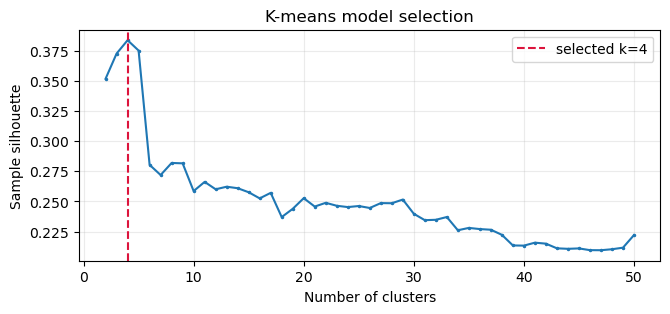

In [7]:
# AI prompt (scope: K-means Monte Carlo): "Select k from 2 through 50 by silhouette using full-data K-means fits and a fixed evaluation sample; then repeat full-data K-means 50 times with new random seeds and measure majority-triplet Hamming errors."
X_all = X.to_numpy()
sample_rng = np.random.default_rng(SEED)
silhouette_indices = sample_rng.choice(len(X_all), size=800, replace=False)
silhouette_rows = []
for k in range(2, 51):
    candidate = KMeans(n_clusters=k, n_init=1, max_iter=150, random_state=SEED).fit(X_all)
    sample_labels = candidate.predict(X_all[silhouette_indices])
    score = silhouette_score(X_all[silhouette_indices], sample_labels)
    silhouette_rows.append({"k": k, "silhouette": score})
silhouette_table = pd.DataFrame(silhouette_rows)
best_k = int(silhouette_table.loc[silhouette_table.silhouette.idxmax(), "k"])
print("Best k:", best_k, "sample silhouette:",
      round(silhouette_table.silhouette.max(), 4))
display(silhouette_table.nlargest(8, "silhouette").sort_values("k").round(4))
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.plot(silhouette_table.k, silhouette_table.silhouette, marker=".", markersize=3)
ax.axvline(best_k, color="crimson", linestyle="--", label=f"selected k={best_k}")
ax.set(xlabel="Number of clusters", ylabel="Sample silhouette", title="K-means model selection")
ax.legend()
plt.show()


### (b)-(c) Cluster-majority triplets and 50-run Hamming summary

For each cluster and each of the three labels, the most frequent true value becomes the assigned value. Ties are broken alphabetically for reproducibility. The majority values are read **after** clustering and are used only to measure clustering quality. Each run reports mean Hamming distance (0–3), score (0–1), and loss (0–1).

In [8]:
def cluster_majorities(cluster_ids, actual):
    label_frame = actual.reset_index(drop=True)
    assigned = pd.DataFrame(index=np.arange(len(cluster_ids)), columns=LABELS)
    rows = []
    for cluster in np.unique(cluster_ids):
        mask = cluster_ids == cluster
        row = {"cluster": cluster, "size": int(mask.sum())}
        for label in LABELS:
            counts = label_frame.loc[mask, label].value_counts()
            tied = sorted(counts[counts == counts.max()].index)
            row[label] = tied[0]
            assigned.loc[mask, label] = row[label]
        rows.append(row)
    return assigned, pd.DataFrame(rows)


monte_carlo_rows = []
for repeat in range(50):
    fitted = KMeans(n_clusters=best_k, n_init=1, max_iter=150,
                    random_state=SEED + repeat).fit(X_all)
    assigned, majority_table = cluster_majorities(fitted.labels_, y)
    monte_carlo_rows.append({"run": repeat + 1, **multi_label_metrics(y, assigned)})
    if repeat == 0:
        first_run_majorities = majority_table.copy()
        first_run_metrics = multi_label_metrics(y, assigned)

print("First run: cluster sizes and majority label triplets")
display(first_run_majorities)
print("First-run metrics:", {k: round(v, 4) for k, v in first_run_metrics.items()})
monte_carlo = pd.DataFrame(monte_carlo_rows)
summary = monte_carlo[["hamming_distance", "hamming_score", "hamming_loss"]].agg(["mean", "std"])
display(summary.round(4))
print("All 50 runs completed; SD uses ddof=1.")


First run: cluster sizes and majority label triplets


,cluster,size,Family,Genus,Species
0,0,3569,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,2097,Hylidae,Hypsiboas,HypsiboasCordobae
2,2,1092,Dendrobatidae,Ameerega,Ameeregatrivittata
3,3,437,Leptodactylidae,Adenomera,AdenomeraAndre


First-run metrics: {'exact_match': 0.7604, 'hamming_distance': 0.5577, 'hamming_score': 0.8141, 'hamming_loss': 0.1859}


,hamming_distance,hamming_score,hamming_loss
mean,0.7417,0.7528,0.2472
std,0.1028,0.0343,0.0343


All 50 runs completed; SD uses ddof=1.


Across 50 random initializations at the silhouette-selected k=4, mean Hamming distance is 0.7417 (SD 0.1028), mean Hamming score is 0.7528 (SD 0.0343), and mean Hamming loss is 0.2472 (SD 0.0343). The first run scores better than this average, illustrating sensitivity to K-means initialization.

## 3. ISLR 12.6.2

The four-observation dissimilarity matrix is

$$D=\begin{pmatrix}
0&0.3&0.4&0.7\\
0.3&0&0.5&0.8\\
0.4&0.5&0&0.45\\
0.7&0.8&0.45&0
\end{pmatrix}.$$

(a) Complete linkage first joins observations 1 and 2 at height 0.30, then 3 and 4 at 0.45, then the two pairs at 0.80 (the largest cross-pair distance).

(b) Single linkage joins 1 and 2 at 0.30, then adds 3 at 0.40, then adds 4 at 0.45 (the smallest intercluster distances).

(c) Cutting the complete-linkage tree into two clusters gives `{1,2}` and `{3,4}`.

(d) Cutting the single-linkage tree into two clusters gives `{1,2,3}` and `{4}`.

(e) Swapping leaves 1 and 2, or 3 and 4, in the complete-linkage drawing gives an equivalent dendrogram: branch membership and fusion heights stay unchanged. The plots below make the heights explicit.

complete merge heights: [0.3, 0.45, 0.8] two-cluster labels: [1, 1, 2, 2]
single merge heights: [0.3, 0.4, 0.45] two-cluster labels: [1, 1, 1, 2]


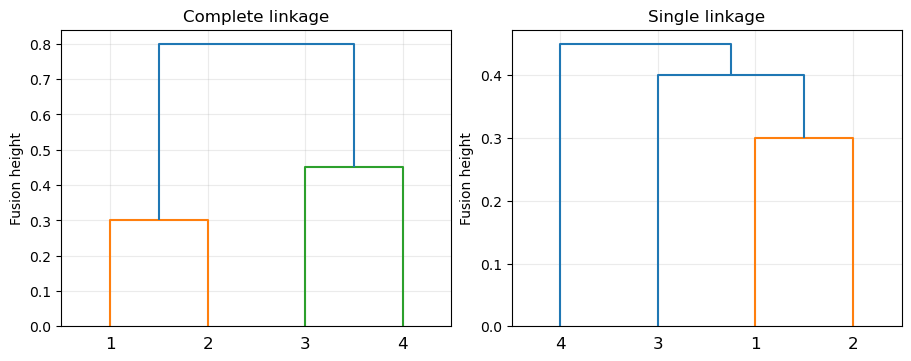

In [9]:
distance_matrix = np.array([[0, .3, .4, .7], [.3, 0, .5, .8],
                            [.4, .5, 0, .45], [.7, .8, .45, 0]])
distances = squareform(distance_matrix)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
for ax, method in zip(axes, ["complete", "single"]):
    hierarchy = linkage(distances, method=method)
    dendrogram(hierarchy, labels=["1", "2", "3", "4"], ax=ax)
    ax.set(title=f"{method.title()} linkage", ylabel="Fusion height")
    print(method, "merge heights:", hierarchy[:, 2].round(2).tolist(),
          "two-cluster labels:", fcluster(hierarchy, t=2, criterion="maxclust").tolist())
plt.show()


## References

- [UCI Anuran Calls (MFCCs)](https://archive.ics.uci.edu/dataset/406/anuran+calls+mfccs), with the supplied data file included under `data/`.
- [scikit-learn multi-label metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#multilabel-ranking-metrics), [OneVsRestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html), and [silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- James et al., [*An Introduction to Statistical Learning*, second edition](https://www.statlearning.com/), Chapter 12, Exercise 2.
